In [1]:
import numpy as np
import math
import json
from scipy.special import erfc
from scipy.stats import poisson
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from tqdm import tqdm
from numba import njit

In [2]:
# ============================================================
# GEOMETRIC PARAMETERS (cm)
# ============================================================
Lx = 0.2
Ly = 0.2
Lz = 0.2

dx = 0.0001
FCCD_cm = 0.1

In [3]:
# ============================================================
# DIFFUSION
# ============================================================
D = 28.9
dt = 1.0
t_max = 10000
Nt = int(t_max / dt)
sigma = math.sqrt(6 * D * dt) * 1e-4

In [4]:
# ============================================================
# LITHIUM
# ============================================================
r_Li = 0.002   # cm
cell_size = r_Li


In [5]:
# ============================================================
# ANNEALING
# ============================================================

'''
valori per detector ORTEC e non MIRION
t_ann = 18 * 60
T_ann = 623
'''

t_ann = 2 * 60 * 60
T_ann = 473

R = 1.98
H = 11800
D0 = 2.5e-3

Ns = 10 ** (21.27 - 2610 / T_ann)
print(f"{Ns:.3e}")
#D_Li = D0 * math.exp(-H / (R * T_ann))
D_Li = 7.66e-9 #cm-2 s

Nd_saturation = 1e14
alpha = 5.5e-10

5.650e+15


In [6]:
def ND_curve(depth, T_ann, t_ann):
    T_ann = T_ann + 273.15
    R = 1.98
    H = 11800
    D0 = 2.5e-3
    
    Ns = 10 ** (21.27 - 2610 / T_ann)
    D_Li = D0 * math.exp(-H / (R * T_ann))

    return Ns * erfc(depth / (2 * np.sqrt(D_Li * t_ann)))

In [7]:

# ============================================================
# SATURATION DEPTH
# ============================================================
depth_list = np.arange(0, 0.11 + dx, dx)
Nd_vals = Ns * erfc(depth_list / (2 * np.sqrt(D_Li * t_ann)))

idx = np.where(Nd_vals - Nd_saturation <= 0)[0][0]
saturation_depth = depth_list[idx]

print("Saturation depth =", saturation_depth * 10, "mm")

Saturation depth = 0.25 mm


0.0263
0.06570000000000001


Text(0, 0.5, 'Concentration (cm$^{-3}$)')

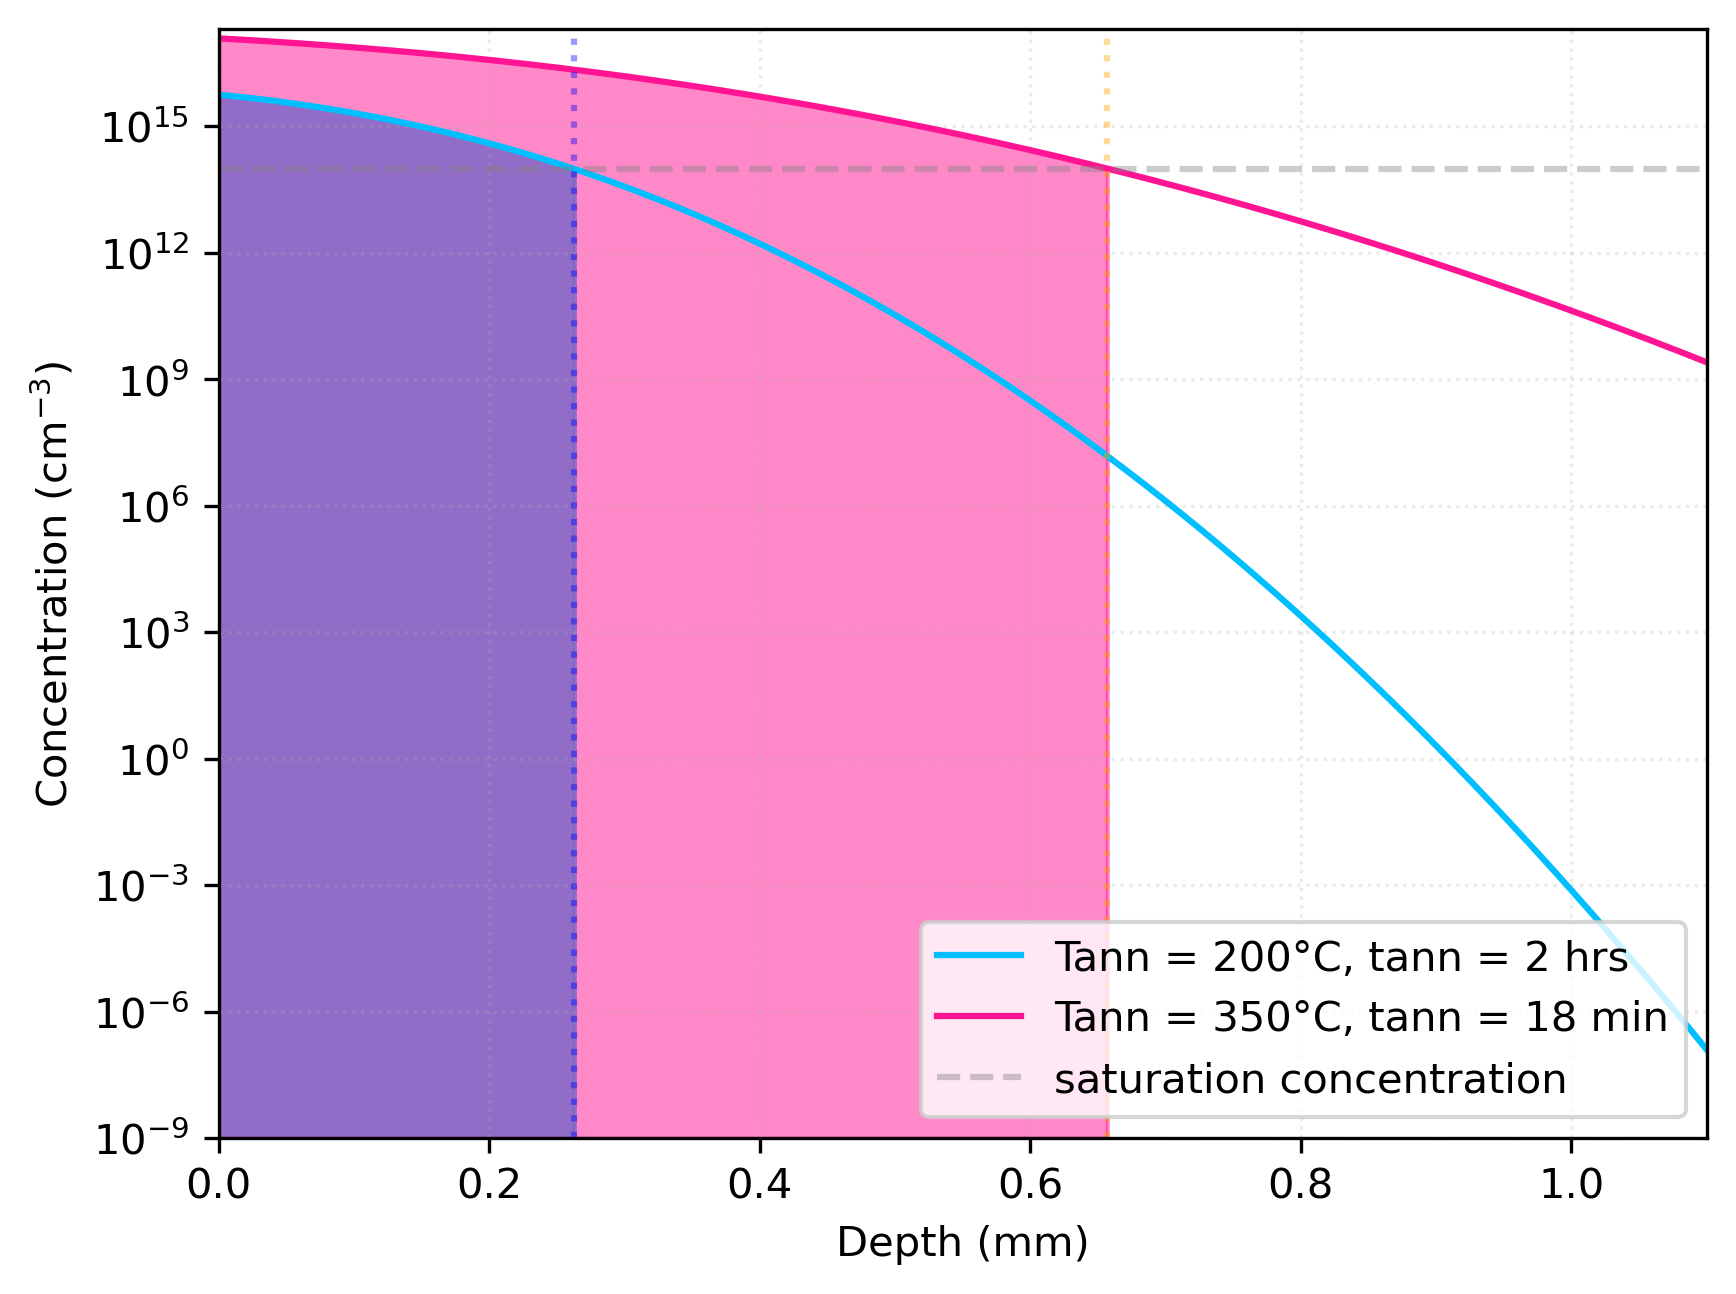

In [8]:

plt.figure(dpi = 300)
curve1 = ND_curve(depth_list, 200, 2*60*60)
curve2 = ND_curve(depth_list, 351, 18*60)

# valore minimo per il riempimento (0 non è possibile in scala log)
ymin_fill = 1e-9


idx1 = np.where(curve1 <= Nd_saturation)[0][0]
sat_depth1 = depth_list[idx1]

mask1 = depth_list <= sat_depth1

plt.plot(
    depth_list*10,
    curve1,
    color='deepskyblue',
    label='Tann = 200°C, tann = 2 hrs'
)

plt.fill_between(
    depth_list[mask1]*10,
    ymin_fill,
    curve1[mask1],
    color='deepskyblue',
    alpha=0.85
)


idx2 = np.where(curve2 <= Nd_saturation)[0][0]
sat_depth2 = depth_list[idx2]

mask2 = depth_list <= sat_depth2


print(sat_depth1)
print(sat_depth2)
plt.plot(
    depth_list*10,
    curve2,
    color='deeppink',
    label='Tann = 350°C, tann = 18 min'
)

plt.fill_between(
    depth_list[mask2]*10,
    ymin_fill,
    curve2[mask2],
    color='deeppink',
    alpha=0.5
)


# --- linea di saturazione ---
plt.hlines(
    Nd_saturation,
    0,
    max(depth_list*10),
    color='grey',
    alpha=0.4,
    ls='--',
    label='saturation concentration'
)


plt.axvline(
    sat_depth1*10,
    color='blue',
    alpha=0.4,
    ls=':'
)

plt.axvline(
    sat_depth2*10,
    color='orange',
    alpha=0.4,
    ls=':'
)

plt.legend(loc = 'lower right')
plt.grid(alpha=0.25, ls=':')

plt.yscale("log")

plt.xlim(0, max(depth_list*10))
plt.ylim(ymin_fill, 2e17)
plt.xlabel('Depth (mm)')
plt.ylabel(r'Concentration (cm$^{-3}$)')

In [14]:
Nd_saturation = 1e14

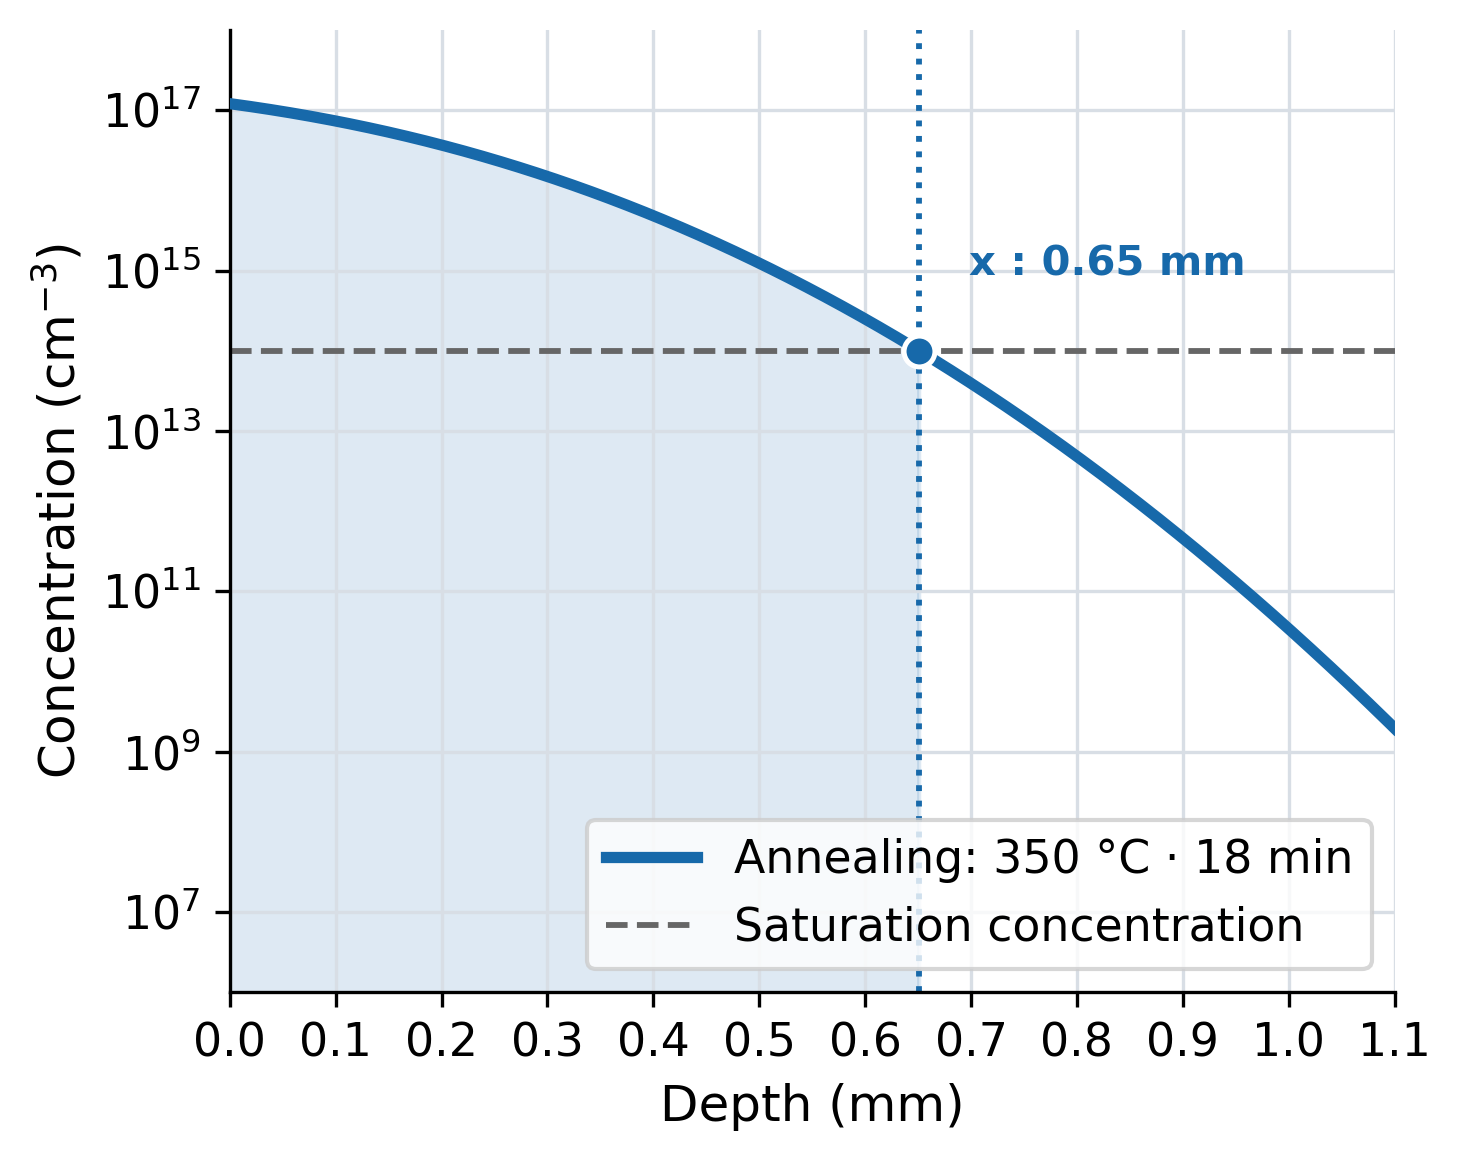

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Calcolo della curva
depth = np.asarray(depth_list)
concentration = np.asarray(ND_curve(depth, 350, 18* 60))

# Primo punto in cui la concentrazione scende sotto la saturazione
crossings = np.flatnonzero(concentration <= Nd_saturation)
if len(crossings) == 0:
    raise ValueError("La curva non raggiunge Nd_saturation nell'intervallo di depth_list.")

i = crossings[0]

# Interpolazione per stimare la profondità di saturazione
if i == 0:
    sat_depth = depth[0]
else:
    sat_depth = np.interp(
        Nd_saturation,
        concentration[i-1:i+1][::-1],
        depth[i-1:i+1][::-1]
    )

x = depth * 10                 # conversione in mm, come nel grafico originale
x_sat = sat_depth * 10
ymin = 1e-9

plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.bbox": "tight",
})

fig, ax = plt.subplots(figsize=(5, 4), dpi=300)

blue = "#1769AA"

ax.plot(
    x, concentration,
    color=blue, linewidth=2.7,
    label="Annealing: 350 °C · 18 min",
    zorder=3
)

# Area fino alla profondità di saturazione
x_fill = np.r_[x[x < x_sat], x_sat]
y_fill = np.r_[concentration[x < x_sat], Nd_saturation]
ax.fill_between(
    x_fill, ymin, y_fill,
    color=blue, alpha=0.14,
    zorder=1
)

ax.axhline(
    Nd_saturation,
    color="#666666", linewidth=1.4, linestyle="--",
    label="Saturation concentration",
    zorder=2
)
ax.axvline(
    x_sat,
    color=blue, linewidth=1.4, linestyle=":",
    zorder=2
)
ax.scatter(
    [x_sat], [Nd_saturation],
    s=55, color=blue, edgecolor="white", linewidth=1.2,
    zorder=4
)

ax.annotate(
    f"x : {x_sat:.2f} mm",
    xy=(x_sat, Nd_saturation),
    xytext=(12, 18),
    textcoords="offset points",
    color=blue,
    fontsize=10,
    fontweight="semibold"
)

ax.set(
    xlim=(0, x.max()),
    ylim=(ymin, 2e17),
    yscale="log",
    xlabel="Depth (mm)",
    ylabel=r"Concentration (cm$^{-3}$)",
)
from matplotlib.ticker import MultipleLocator

ax.xaxis.set_major_locator(MultipleLocator(0.1))  # una tacca ogni 1 mm
ax.set_xlim(0, x.max())
ax.set_ylim(1e6, 1e18)
ax.grid(which="major", color="#D8DEE5", linewidth=0.8)
ax.grid(which="minor", color="#E9EDF1", linewidth=0.5, alpha=0.6)
ax.legend(loc="lower right", frameon=True)

fig.tight_layout()
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

L = 2.0  # lato del cubo in mm

# Profilo lungo x
x = np.linspace(0, L, 300)
y = np.linspace(0, L, 60)

# ND_curve usa la profondità in cm
concentration = np.asarray(
    ND_curve(x / 10, 350, 18 * 60),
    dtype=float
)

# Limiti della concentrazione
c_min = 1e4
c_max = 1e18

# Altezza nel cubo: concentrazione in scala logaritmica
c_plot = np.clip(concentration, c_min, c_max)

z = L * (
    (np.log10(c_plot) - np.log10(c_min))
    / (np.log10(c_max) - np.log10(c_min))
)

# Estensione della curva lungo y
#X, Y = np.meshgrid(x, y)
Z = np.tile(z, (len(y), 1))
C = np.tile(c_plot, (len(y), 1))

fig = plt.figure(figsize=(7, 5), dpi=300)
ax = fig.add_subplot(111, projection="3d")

cmap = plt.get_cmap("viridis")
norm = LogNorm(vmin=c_min, vmax=c_max)

ax.plot_surface(
    X, Y, Z,
    facecolors=cmap(norm(C)),
    rcount=len(y),
    ccount=len(x),
    linewidth=0,
    antialiased=True,
    shade=False,
    alpha=0.85,
)

# Curva originale sulla faccia y = 0
ax.plot(
    x, np.zeros_like(x), z,
    color="#1769AA",
    linewidth=2.5,
    zorder=5,
)

# Rimuove la griglia degli assi

ax.grid(False)

# Fette quadrate perpendicolari a x ogni 10 µm = 0.01 mm
slice_step_mm = 0.25
x_slices = np.arange(0, L + slice_step_mm / 2, slice_step_mm)

slices = [
    [
        (x_slice, 0, 0),
        (x_slice, L, 0),
        (x_slice, L, L),
        (x_slice, 0, L),
    ]
    for x_slice in x_slices
]

ax.add_collection3d(
    Poly3DCollection(
        slices,
        facecolors=(0.55, 0.75, 0.90, 0.015),
        edgecolors=(0.35, 0.45, 0.55, 0.25),
        linewidths=0.3,
    )
)

# Spigoli del cubo 2 × 2 × 2 mm
for a in (0, L):
    for b in (0, L):
        ax.plot([0, L], [a, a], [b, b], color="gray", lw=0.8)
        ax.plot([a, a], [0, L], [b, b], color="gray", lw=0.8)
        ax.plot([a, a], [b, b], [0, L], color="gray", lw=0.8)

# Tacche x e y in mm
xy_ticks = [0, 1, 2]
xy_ticks = np.arange(0, L + 0.25, 0.5)

ax.set_xticks(xy_ticks)
ax.set_yticks(xy_ticks)

ax.set_xticklabels([f"{v:g}" for v in xy_ticks])
ax.set_yticklabels([f"{v:g}" for v in xy_ticks])

# Tacche z etichettate con la concentrazione
c_ticks = np.array([1e4, 1e8, 1e12, 1e16, 1e18])

z_ticks = L * (
    (np.log10(c_ticks) - np.log10(c_min))
    / (np.log10(c_max) - np.log10(c_min))
)

ax.set_zticks(z_ticks)
ax.set_zticklabels([
    r"$10^4$",
    r"$10^8$",
    r"$10^{12}$",
    r"$10^{16}$",
    r"$10^{18}$",
])

ax.tick_params(axis="x", labelsize=10, pad=8)
ax.tick_params(axis="y", labelsize=10, pad=8)
ax.tick_params(axis="z", labelsize=10, pad=8)

ax.set(
    xlabel="Depth x (mm)",
    ylabel="y (mm)",
    zlabel=r"Concentration (cm$^{-3}$)",
    xlim=(0, L),
    ylim=(0, L),
    zlim=(0, L),
)

ax.xaxis.labelpad = 10
ax.yaxis.labelpad = 10
ax.zaxis.labelpad = 10

ax.set_box_aspect((1, 1, 1), zoom=0.85)
ax.view_init(elev=25, azim=-55)
ax.zaxis._axinfo["juggled"] = (1, 2, 0)

# Margini per evitare che etichette e ticks vengano tagliati
fig.subplots_adjust(
    left=0.05,
    right=0.80,
    bottom=0.12,
    top=0.95,
)

plt.show()
plt.show()

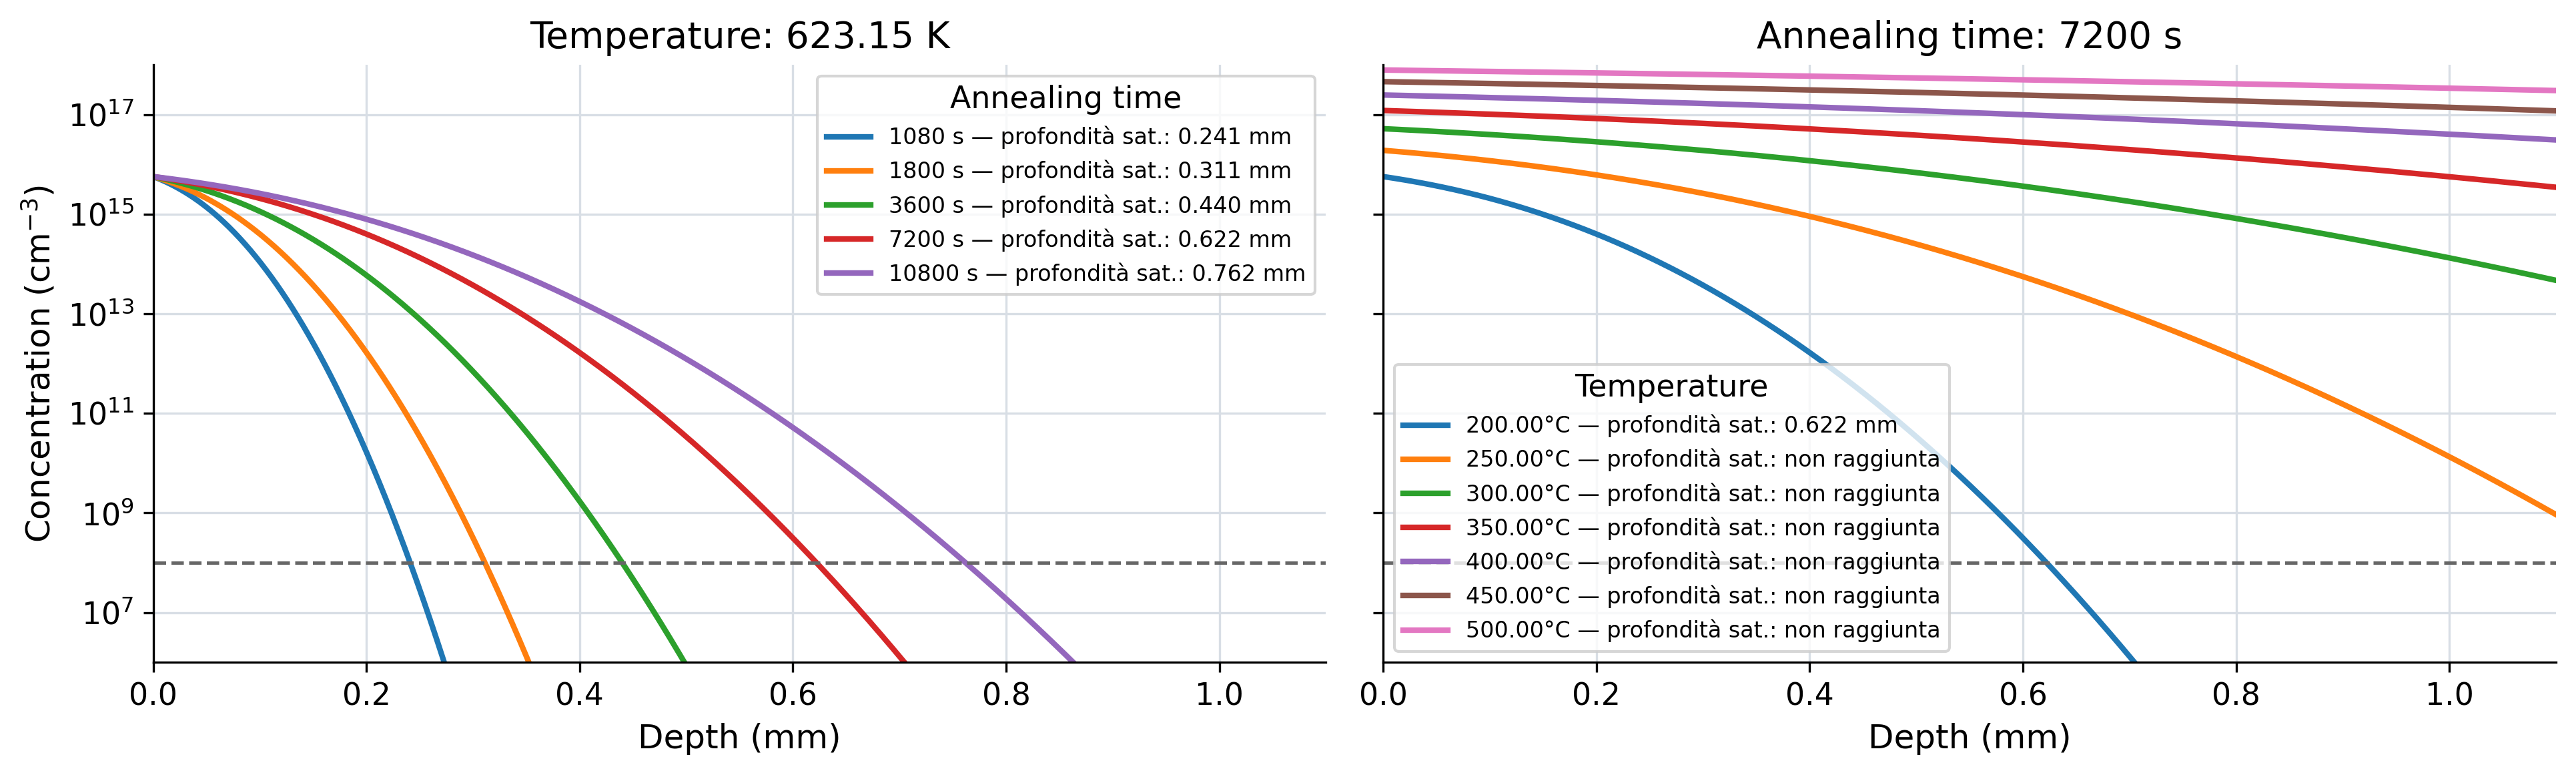

In [11]:
import numpy as np
import matplotlib.pyplot as plt

depth = np.asarray(depth_list)
x = depth * 10  # mm

times_s = [18 * 60, 30 * 60, 60 * 60, 120 * 60, 180 * 60]
temperatures_C = [200, 250, 300, 350, 400, 450, 500]

def saturation_depth_mm(x, concentration, threshold):
    """Primo attraversamento della soglia, interpolato in scala logaritmica."""
    valid = np.isfinite(x) & np.isfinite(concentration) & (concentration > 0)
    x_valid = x[valid]
    c_valid = concentration[valid]

    crossings = np.flatnonzero(
        (c_valid[:-1] - threshold) * (c_valid[1:] - threshold) <= 0
    )
    if len(crossings) == 0:
        return None

    i = crossings[0]
    if c_valid[i] == c_valid[i + 1]:
        return x_valid[i]

    return np.interp(
        np.log10(threshold),
        np.log10([c_valid[i], c_valid[i + 1]])[::-1]
        if c_valid[i] > c_valid[i + 1]
        else np.log10([c_valid[i], c_valid[i + 1]]),
        [x_valid[i], x_valid[i + 1]][::-1]
        if c_valid[i] > c_valid[i + 1]
        else [x_valid[i], x_valid[i + 1]],
    )

def curve_label(parameter, concentration):
    d_sat = saturation_depth_mm(x, concentration, Nd_saturation)
    depth_text = f"{d_sat:.3f} mm" if d_sat is not None else "non raggiunta"
    return f"{parameter} — profondità sat.: {depth_text}"

fig, axes = plt.subplots(1, 2, figsize=(13, 4), dpi=300, sharey=True)

# Temperatura fissa: 350 °C = 623,15 K
for seconds in times_s:
    concentration = np.asarray(ND_curve(depth, 200, seconds))
    axes[0].plot(
        x, concentration, linewidth=2,
        label=curve_label(f"{seconds} s", concentration)
    )

axes[0].set_title("Temperature: 623.15 K")
axes[0].set_xlabel("Depth (mm)")
axes[0].set_ylabel(r"Concentration (cm$^{-3}$)")
axes[0].legend(title="Annealing time", fontsize=8)

# Tempo fisso: 2 ore = 7200 s
for temperature_C in temperatures_C:
    concentration = np.asarray(ND_curve(depth, temperature_C, 2*60*60))
    temperature_K = temperature_C + 273.15
    axes[1].plot(
        x, concentration, linewidth=2,
        label=curve_label(f"{temperature_C:.2f}°C", concentration)
    )

axes[1].set_title("Annealing time: 7200 s")
axes[1].set_xlabel("Depth (mm)")
axes[1].legend(title="Temperature", fontsize=8)

for ax in axes:
    ax.axhline(Nd_saturation, color="#666666", linestyle="--", linewidth=1.2)
    ax.set_xlim(0, x.max())
    ax.set_ylim(1e6, 1e18)
    ax.set_yscale("log")
    ax.grid(which="major", color="#D8DEE5", linewidth=0.8)
    ax.grid(which="minor", color="#E9EDF1", linewidth=0.5, alpha=0.6)

fig.tight_layout()
plt.show()

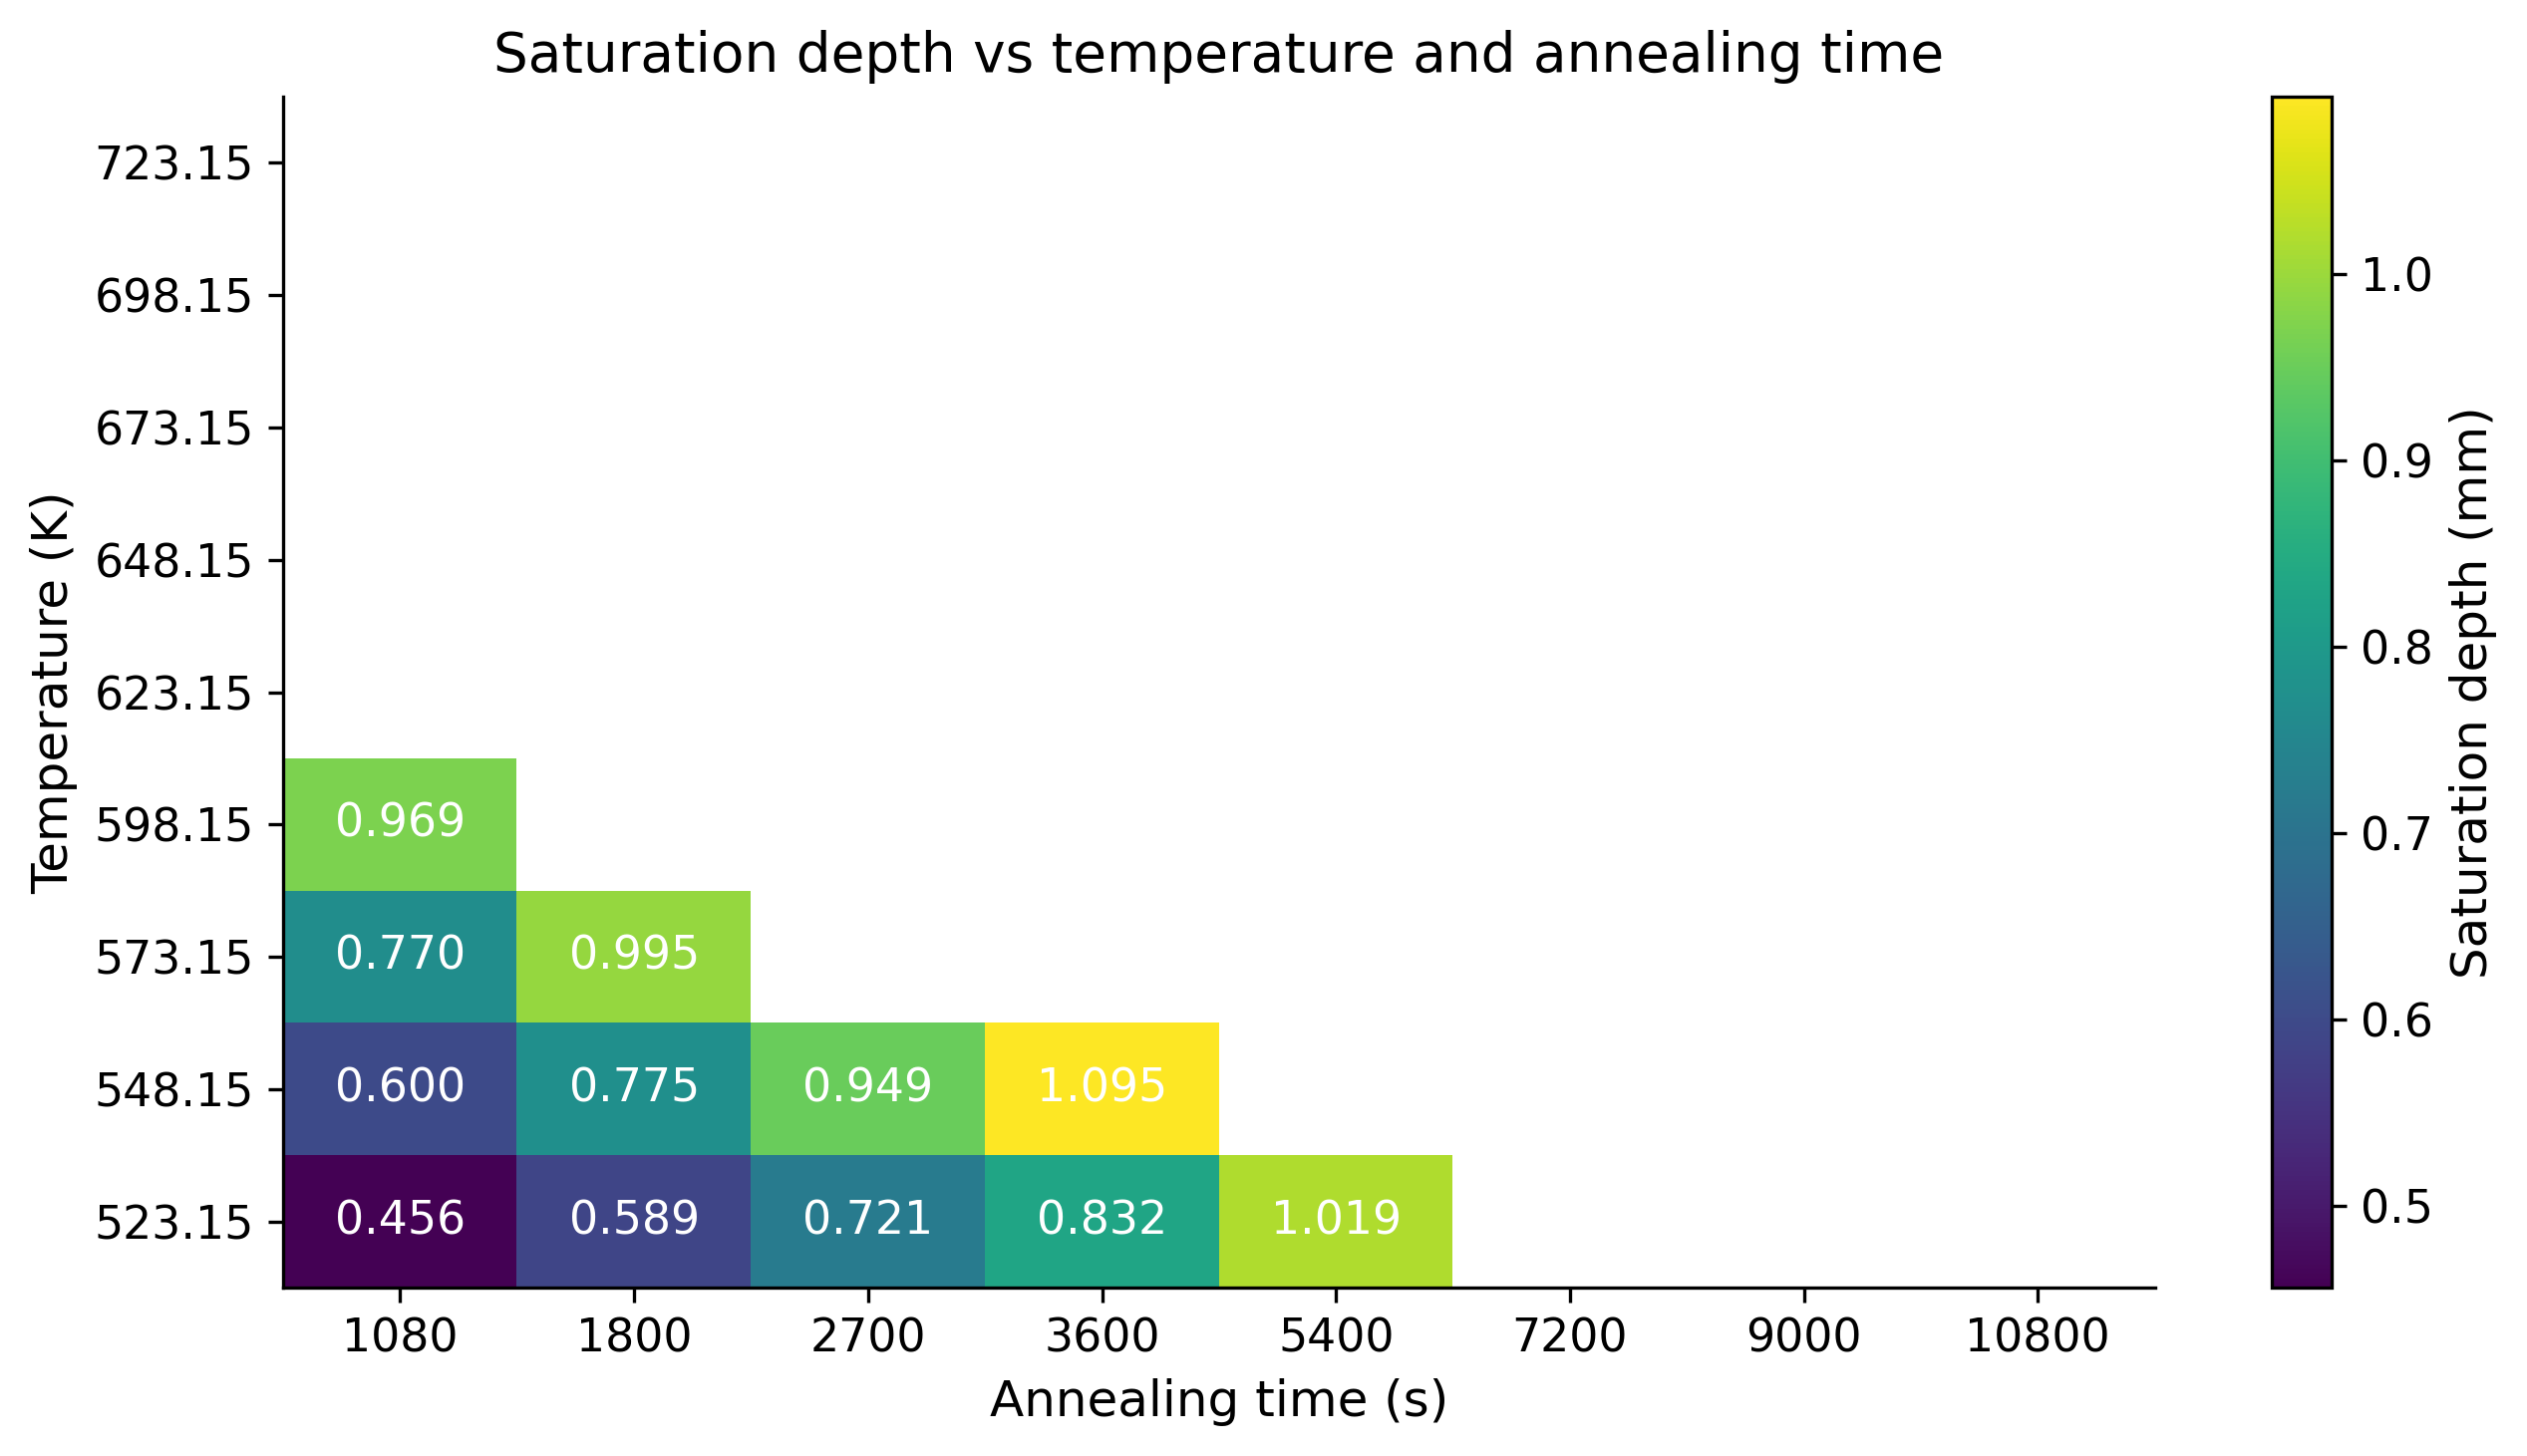

In [12]:
import numpy as np
import matplotlib.pyplot as plt

depth = np.asarray(depth_list)
x_mm = depth * 10

times_s = np.array([18, 30, 45, 60, 90, 120, 150, 180]) * 60
temperatures_C = np.array([250, 275, 300, 325, 350, 375, 400, 425, 450, ])
temperatures_K = temperatures_C + 273.15

def saturation_depth_mm(x, concentration, threshold):
    """Restituisce il primo attraversamento della soglia, in mm."""
    valid = np.isfinite(x) & np.isfinite(concentration) & (concentration > 0)
    x = x[valid]
    c = concentration[valid]

    crossings = np.flatnonzero(
        (c[:-1] - threshold) * (c[1:] - threshold) <= 0
    )
    if len(crossings) == 0:
        return np.nan

    i = crossings[0]
    if c[i] == c[i + 1]:
        return x[i]

    fraction = (
        (np.log10(threshold) - np.log10(c[i]))
        / (np.log10(c[i + 1]) - np.log10(c[i]))
    )
    return x[i] + fraction * (x[i + 1] - x[i])

# Righe: temperature; colonne: tempi
rdr_mm = np.full((len(temperatures_C), len(times_s)), np.nan)

for i, temperature_C in enumerate(temperatures_C):
    for j, time_s in enumerate(times_s):
        concentration = np.asarray(
            ND_curve(depth, temperature_C, time_s)
        )
        rdr_mm[i, j] = saturation_depth_mm(
            x_mm, concentration, Nd_saturation
        )

fig, ax = plt.subplots(figsize=(9, 5), dpi=300)

image = ax.imshow(
    rdr_mm,
    origin="lower",
    aspect="auto",
    cmap="viridis"
)

ax.set_xticks(range(len(times_s)), labels=times_s)
ax.set_yticks(range(len(temperatures_K)), labels=temperatures_K)
ax.set_xlabel("Annealing time (s)")
ax.set_ylabel("Temperature (K)")
ax.set_title("Saturation depth vs temperature and annealing time")

for i in range(len(temperatures_K)):
    for j in range(len(times_s)):
        value = rdr_mm[i, j]
        label = f"{value:.3f}" if np.isfinite(value) else "—"
        ax.text(j, i, label, ha="center", va="center", color="white")

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Saturation depth (mm)")

fig.tight_layout()
plt.show()